# Прогнозирование оттока клиентов

## 0. Задача
По данным о покупках и активности клиента нужно определить, уйдёт ли он. Целевая переменная — `churn`: 0 — клиент остался, 1 — ушёл. Это задача классификации.

## 1. Чтение данных

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv('dataset.csv')
df.columns = df.columns.str.strip()
print('Размер:', df.shape)
print('Дубликаты:', df.duplicated().sum())
df = df.drop_duplicates().copy()
display(df.head())
df.info()

Размер: (15000, 30)
Дубликаты: 0


,customer_id,gender,age,country,city,signup_date,last_purchase_date,acquisition_channel,device_type,subscription_type,is_premium_user,total_visits,avg_session_time,pages_per_session,email_open_rate,email_click_rate,total_spent,avg_order_value,discount_used,coupon_code,support_tickets,refund_requested,delivery_delay_days,payment_method,satisfaction_score,nps_score,marketing_spend_per_user,lifetime_value,last_3_month_purchase_freq,churn
0,10001,Male,52.0,India,Berlin,2022-05-10 00:00:00,2024-12-31 00:00:00,Email,Tablet,Annual,1,7,13.903745,5.415164,0.67,0.26,559.524958,65.246704,0,NEW20,0,0,3,UPI,3.0,10,27.56,915.310827,14,0
1,10002,NaN,35.0,Germany,Mumbai,2024-06-16 00:00:00,2024-05-07 00:00:00,Organic,Desktop,Monthly,0,19,5.112528,5.352441,0.70,0.37,356.491344,48.473887,1,NEW20,5,0,3,BKash,3.0,7,15.15,2079.960938,11,0
2,10003,Female,27.0,Germany,London,2023-08-23 00:00:00,2024-04-28 00:00:00,Email,Mobile,Annual,1,18,9.742749,3.594719,0.47,0.44,689.332196,77.815371,0,NaN,1,0,2,UPI,5.0,6,13.51,1379.150885,9,0
3,10004,Female,36.0,India,Mumbai,2024-01-28 00:00:00,2023-05-20 00:00:00,Facebook Ads,Tablet,Annual,1,16,9.642654,2.949531,0.58,0.37,445.429636,71.712192,0,NaN,0,0,2,PayPal,4.0,6,25.65,774.652684,7,0
4,10005,Male,29.0,USA,Hamburg,2023-07-21 00:00:00,2024-04-07 00:00:00,Referral,Mobile,Monthly,0,12,7.791291,2.405539,0.05,0.16,686.286022,44.990246,1,NaN,2,1,4,BKash,3.0,1,12.39,87.680409,11,0


<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   customer_id                 15000 non-null  int64  
 1   gender                      14262 non-null  str    
 2   age                         13800 non-null  float64
 3   country                     15000 non-null  str    
 4   city                        15000 non-null  str    
 5   signup_date                 15000 non-null  str    
 6   last_purchase_date          15000 non-null  str    
 7   acquisition_channel         15000 non-null  str    
 8   device_type                 15000 non-null  str    
 9   subscription_type           15000 non-null  str    
 10  is_premium_user             15000 non-null  int64  
 11  total_visits                15000 non-null  int64  
 12  avg_session_time            15000 non-null  float64
 13  pages_per_session           15000 non-null

## 2. Обучающая и тестовая выборки
Убираем идентификатор клиента. Даты в этой работе тоже не используем, чтобы не кодировать каждую дату как отдельную категорию. На обучение оставляем 80% данных. Соотношение классов сохраняем с помощью `stratify`.

In [42]:
X = df.drop(columns=['churn', 'customer_id', 'signup_date', 'last_purchase_date'])
y = df['churn'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Классы на train (%):')
print(y_train.value_counts(normalize=True).mul(100).round(2))

Train: (12000, 26) Test: (3000, 26)
Классы на train (%):
churn
0    84.68
1    15.32
Name: proportion, dtype: float64


## 3. Основные характеристики и графики
Посмотрим статистики, пропуски и распределения признаков на обучающей выборке.

,"Пропуски, %"
coupon_code,40.83
age,8.06
total_spent,7.07
gender,4.88
satisfaction_score,4.78


,count,mean,std,min,25%,50%,75%,max
age,11033.0,35.24,10.36,-4.00,28.00,35.00,42.00,95.00
is_premium_user,12000.0,0.30,0.46,0.00,0.00,0.00,1.00,1.00
total_visits,12000.0,15.00,3.88,3.00,12.00,15.00,18.00,31.00
avg_session_time,12000.0,7.99,2.99,0.01,5.93,7.96,10.02,19.12
pages_per_session,12000.0,4.01,1.48,0.02,3.00,4.01,5.02,10.84
email_open_rate,12000.0,0.49,0.29,0.00,0.24,0.49,0.75,1.00
email_click_rate,12000.0,0.25,0.14,0.00,0.13,0.25,0.38,0.50
total_spent,11151.0,524.90,484.88,0.27,300.73,498.34,702.21,15910.43
avg_order_value,12000.0,60.14,24.75,0.07,43.25,60.08,77.00,154.55
discount_used,12000.0,0.50,0.50,0.00,0.00,0.00,1.00,1.00


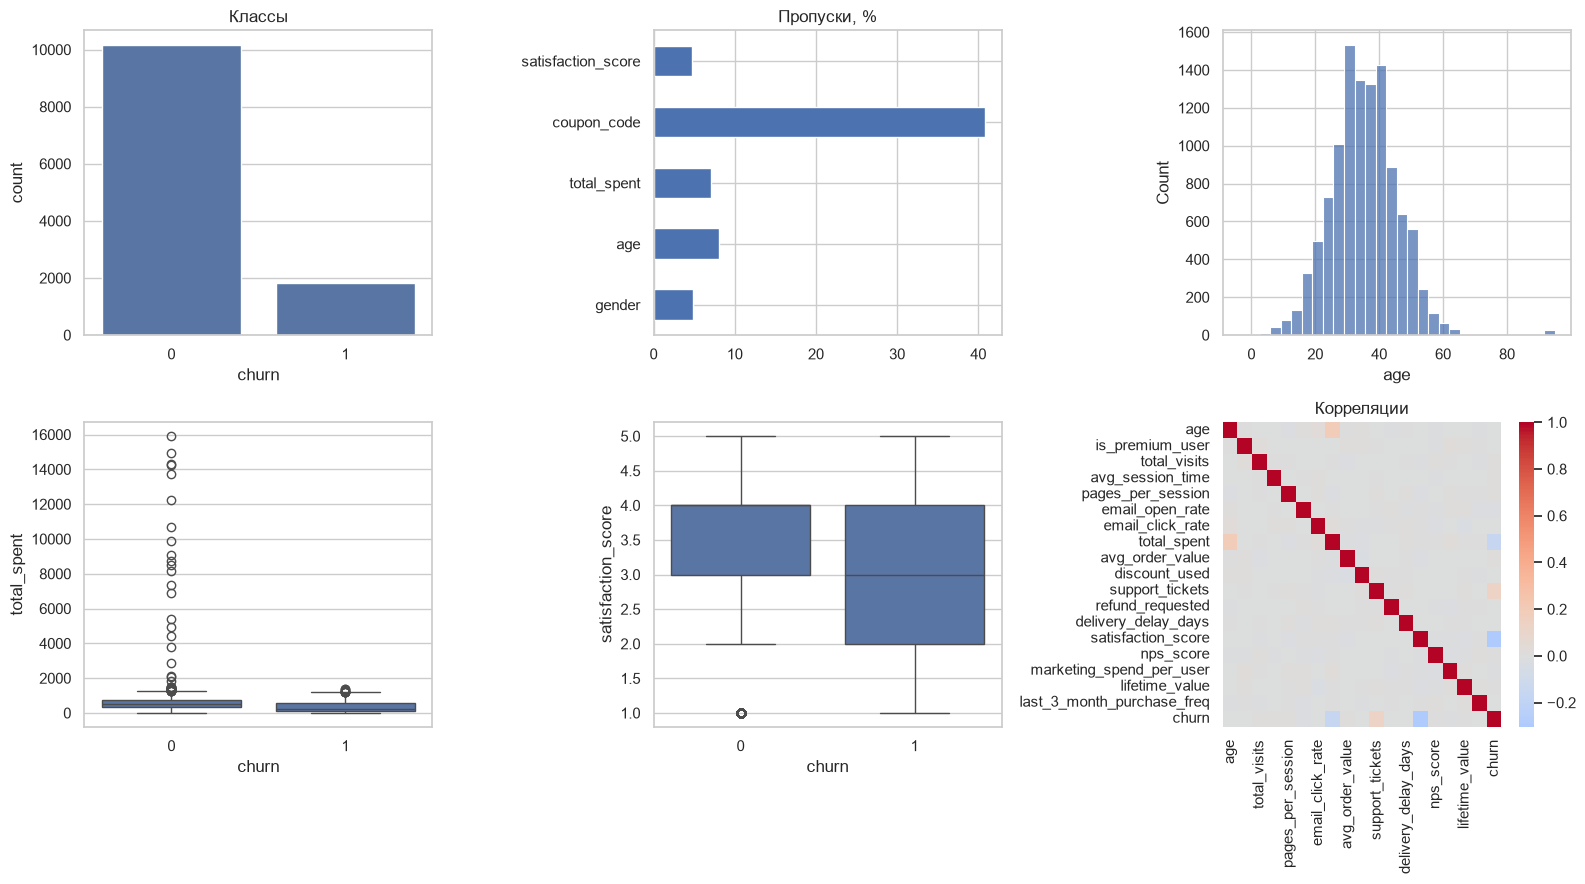

,Корреляция с churn
satisfaction_score,-0.303595
total_spent,-0.158492
support_tickets,0.125070
total_visits,0.016129
avg_session_time,0.016115
email_open_rate,-0.015278
pages_per_session,0.013610
marketing_spend_per_user,-0.010422
avg_order_value,0.008413
email_click_rate,-0.004069


In [43]:
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
missing = X_train.isna().mean().mul(100)
display(missing[missing > 0].sort_values(ascending=False).round(2).to_frame('Пропуски, %'))
display(X_train[num_cols].describe().T.round(2))

plot_data = X_train.assign(churn=y_train)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.countplot(data=plot_data, x='churn', ax=axes[0, 0])
axes[0, 0].set_title('Классы')
missing[missing > 0].plot.barh(ax=axes[0, 1])
axes[0, 1].set_title('Пропуски, %')
sns.histplot(data=plot_data, x='age', bins=30, ax=axes[0, 2])
sns.boxplot(data=plot_data, x='churn', y='total_spent', ax=axes[1, 0])
sns.boxplot(data=plot_data, x='churn', y='satisfaction_score', ax=axes[1, 1])
corr = plot_data[num_cols + ['churn']].corr()
sns.heatmap(corr, cmap='coolwarm', center=0, ax=axes[1, 2])
axes[1, 2].set_title('Корреляции')
plt.tight_layout()
plt.show()
display(corr['churn'].drop('churn').sort_values(key=abs, ascending=False).to_frame('Корреляция с churn'))

Клиентов, которые остались, заметно больше. Поэтому высокая доля правильных ответов ещё не означает, что модель хорошо находит отток. Кроме accuracy будем смотреть F1 и полноту.

В исходных данных самые заметные связи с оттоком были у удовлетворённости, суммы покупок и числа обращений в поддержку. Большинство остальных числовых признаков связано с целью слабее. У суммы покупок виден большой разброс и отдельные высокие значения.

## 4. Выбросы
Проверим возраст: значения вне диапазона от 0 до 120 считаем ошибочными и заменяем пропусками. Большие суммы покупок не удаляем автоматически: по одной величине суммы нельзя определить, ошибочная ли запись.

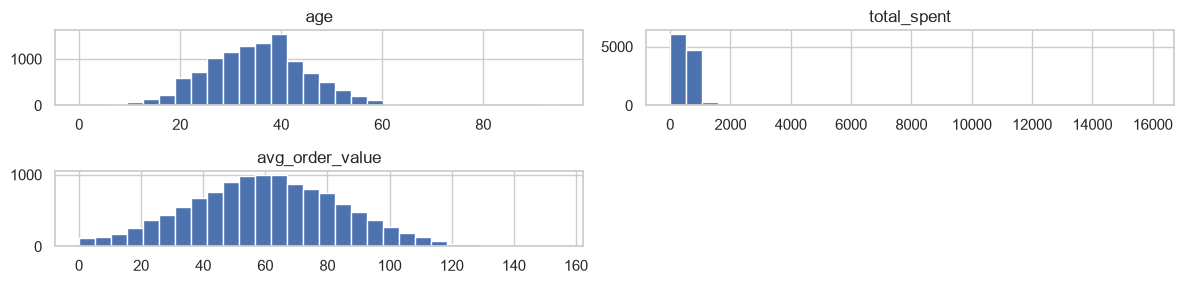

In [44]:
X_train = X_train.copy()
X_test = X_test.copy()
for data in [X_train, X_test]:
    data.loc[~data['age'].between(0, 120), 'age'] = np.nan

X_train[['age', 'total_spent', 'avg_order_value']].hist(bins=30, figsize=(12, 3))
plt.tight_layout()
plt.show()

## 5–7. Пропуски, категории и нормализация
Числовые пропуски заполняем медианами. Для категориальных создаём значение `Missing`, затем применяем one-hot-кодирование. Так отсутствие промокода останется отдельным значением.

Числовые признаки нормализуем: kNN сравнивает расстояния, поэтому сумма покупок не должна перевешивать остальные признаки только из-за своего масштаба.

In [45]:
# Пустые строки тоже считаем пропусками.
for data in [X_train, X_test]:
    for col in cat_cols:
        values = data[col].astype('string').str.strip().replace('', pd.NA)
        data[col] = values.astype(object).where(values.notna(), np.nan)

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('fill', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('fill', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encode', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

## 8. Метод ближайших соседей
Используем kNN: он предсказывает класс по похожим клиентам и позволяет проверить влияние числа соседей. Возьмём веса по расстоянию, чтобы более близкие объекты сильнее влияли на ответ.

Число соседей выберем по F1 на трёх фолдах обучающей выборки. Подготовка признаков включена в Pipeline, поэтому медианы и масштабы не вычисляются по проверочному фолду.

Лучшее число соседей: 3
F1 на кросс-валидации: 0.1928


,param_knn__n_neighbors,mean_test_score,std_test_score
0,3,0.192806,0.009030
1,5,0.143263,0.007430
2,11,0.059390,0.008022
3,21,0.023395,0.005393
4,41,0.003254,0.002655
5,81,0.000000,0.000000


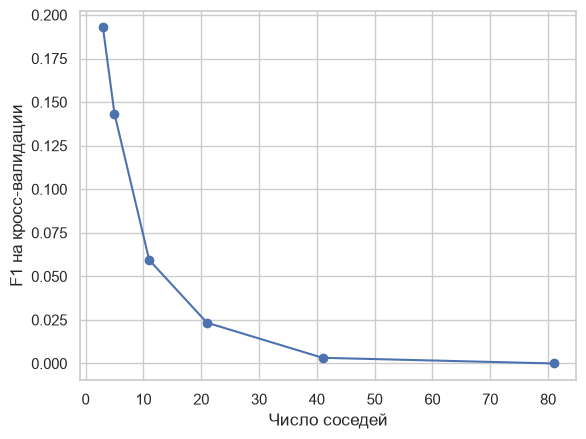

In [46]:
model = Pipeline([
    ('prepare', preprocessor),
    ('knn', KNeighborsClassifier(weights='distance'))
])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
search = GridSearchCV(model, {'knn__n_neighbors': [3, 5, 11, 21, 41, 81]},
                      scoring='f1', cv=cv, n_jobs=-1)
search.fit(X_train, y_train)
knn = search.best_estimator_
print('Лучшее число соседей:', search.best_params_['knn__n_neighbors'])
print('F1 на кросс-валидации:', round(search.best_score_, 4))
scores = pd.DataFrame(search.cv_results_)
display(scores[['param_knn__n_neighbors', 'mean_test_score', 'std_test_score']])
plt.plot(scores['param_knn__n_neighbors'].astype(int), scores['mean_test_score'], 'o-')
plt.xlabel('Число соседей')
plt.ylabel('F1 на кросс-валидации')
plt.show()

## 9. Ошибки и матрицы рассогласования
Проверим выбранный вариант на train и test. Ошибка — доля неправильных ответов, то есть `1 − accuracy`. В матрицах строки показывают истинные классы, столбцы — предсказанные.

,Ошибка,F1,Полнота
train,0.0000,1.0000,1.0000
test,0.1587,0.2197,0.1457


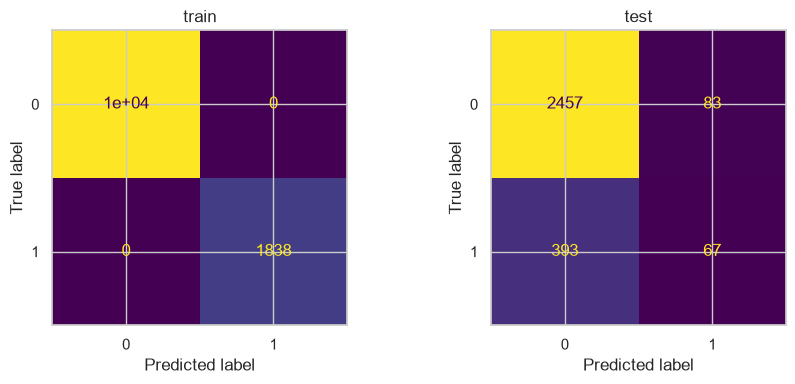

              precision    recall  f1-score   support

           0      0.862     0.967     0.912      2540
           1      0.447     0.146     0.220       460

    accuracy                          0.841      3000
   macro avg      0.654     0.556     0.566      3000
weighted avg      0.798     0.841     0.806      3000



In [47]:
pred_train = knn.predict(X_train)
pred_test = knn.predict(X_test)
results = pd.DataFrame({
    'Ошибка': [1 - accuracy_score(y_train, pred_train), 1 - accuracy_score(y_test, pred_test)],
    'F1': [f1_score(y_train, pred_train, zero_division=0), f1_score(y_test, pred_test, zero_division=0)],
    'Полнота': [recall_score(y_train, pred_train, zero_division=0), recall_score(y_test, pred_test, zero_division=0)]
}, index=['train', 'test'])
display(results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, target, pred, name in zip(axes, [y_train, y_test],
                                [pred_train, pred_test], ['train', 'test']):
    ConfusionMatrixDisplay.from_predictions(target, pred, labels=[0, 1], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()
print(classification_report(y_test, pred_test, digits=3, zero_division=0))

У kNN с весами по расстоянию ошибка на train может быть нулевой, потому что при проверке обучающей строки её ближайший сосед — она сама. Поэтому основной результат смотрим на test.

Особенно важна нижняя строка тестовой матрицы: она показывает, сколько ушедших клиентов найдено и сколько пропущено.

## 13. Выводы

In [48]:
k = search.best_params_['knn__n_neighbors']
tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()
if tp == 0:
    comment = 'Модель не нашла ни одного ушедшего клиента. Несмотря на долю правильных ответов, для обнаружения оттока этот результат неудовлетворительный.'
else:
    comment = f'Модель нашла {tp} из {tp + fn} ушедших клиентов, пропустила {fn} и дала {fp} ложных тревог.'

display(Markdown(
    f'В работе использован датасет из {len(df)} клиентов. Пропуски были заполнены, '
    'категориальные признаки закодированы, числовые — нормализованы. '
    f'На обучение выделено {len(y_train)} объектов, на тестирование — {len(y_test)}.\n\n'
    f'Среди проверенных вариантов выбран kNN с k = {k}. '
    f'Ошибка на train составила {results.loc["train", "Ошибка"]:.3f}, '
    f'на test — {results.loc["test", "Ошибка"]:.3f}. '
    f'На test F1 = {results.loc["test", "F1"]:.3f}, '
    f'полнота = {results.loc["test", "Полнота"]:.3f}. {comment}\n\n'
    'Классы несбалансированы, поэтому оценивать результат только по accuracy было бы неправильно. '
    'Подбор числа соседей выполнен на обучающих данных; тестовая выборка использована для итоговой проверки.'
))

В работе использован датасет из 15000 клиентов. Пропуски были заполнены, категориальные признаки закодированы, числовые — нормализованы. На обучение выделено 12000 объектов, на тестирование — 3000.

Среди проверенных вариантов выбран kNN с k = 3. Ошибка на train составила 0.000, на test — 0.159. На test F1 = 0.220, полнота = 0.146. Модель нашла 67 из 460 ушедших клиентов, пропустила 393 и дала 83 ложных тревог.

Классы несбалансированы, поэтому оценивать результат только по accuracy было бы неправильно. Подбор числа соседей выполнен на обучающих данных; тестовая выборка использована для итоговой проверки.